# ICT-15h — Pont nº 1-bis (chantier 2/3) : le régime asymétrique confirme le négatif de σ

*See [#9531](https://github.com/jsboige/CoursIA/issues/9531).*

> **Twin C# .NET de `ICT-15h-Bridge1bis-AsymmetricFamily-Python.ipynb`** (Python). Même plan cellule à cellule que la source, mêmes instances (grilles 5×5×5, puits témoin a = 1,0 · b = 2,0 · c = 0,8), mêmes comparaisons numériques. Le module `ict.basin_asym` est porté à la main sur la BCL .NET 9 : les quantités **déterministes** (profil des minima, couplage σ–w **brut** (+0.746), tailles d'échantillon n = 250 → 42, null n = 20) sont identiques à la source au dernier chiffre affiché ; le couplage σ–w **stratifié** dépend du tirage de min_per_cell points par cellule (graine fixe 0 mais RNG différent) : Python +0.471, C# +0.427 — écart de sélection documenté ; seul le générateur pseudo-aléatoire change (xorshift64* seedé, déterministe par graine, là où numpy utilise PCG64 — même choix que le jumeau ICT-15, #27734), donc les grandeurs **stochastiques** (partielles, null p95, écarts-types) se comparent à tolerance de Monte-Carlo près, donnée dans chaque lecture. La figure ScottPlot remplace matplotlib.

Le **chantier 1/3** (`ICT-15f-Bridge1bis-DecoupledFamily-Python`, module `ict.basin_family`,
PR #9540) a tranche **CONFIRMED-NEGATIVE** sur une famille de double-puits
**symetriques** $V(x) = a x^4 - b x^2$ ou $\\sigma = V''(x^*)$ et la largeur de
bassin $w$ varient *independamment par construction*. La stabilite locale
$\\sigma$ n'a aucun pouvoir predictif propre pour la recuperabilite une fois la
largeur ET la barriere controlees ; c'est la geometrie du bassin qui gouverne.

**Mais** le double-puits symetrique a une propriete restrictive : ses deux minima
sont **interchangeables** (meme profondeur, meme $\\sigma$, meme largeur, meme
barriere). Le verdict porte donc sur un regime geometrique particulier. La
question de ce chantier 2/3 : **le verdict tient-il dans un regime ou les deux
bassins ne sont PLUS interchangeables** ?

On construit pour cela le double-puits **asymetrique** $V(x) = a x^4 - b x^2 + c x^3$
(terme cubique anti-symetrique sous $x \\mapsto -x$), dont les deux minima ont des
profondeurs, courbures, largeurs et barrieres **differentes** -- la richesse
geometrique que le regime symetrique ne pouvait pas sonder.


> **Statut épistémique** — **Sans verdict à ce jour** : aucune ligne de la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md) ne concerne ce notebook ; son statut épistémique sera porté par la matrice le cas échéant.

> **Acquis et parenté** : chantier 2/3 de la famille Pont #1-bis — le verdict CONFIRMED-NEGATIVE que ce régime asymétrique **généralise** est celui du chantier 1/3, [ICT-15f-Bridge1bis-DecoupledFamily-Python](ICT-15f-Bridge1bis-DecoupledFamily-Python.ipynb) ; le chantier 3/3 est [ICT-15i-Bridge1bis-2DLandscape-Python](ICT-15i-Bridge1bis-2DLandscape-Python.ipynb).

## 1. Le substrat asymetrique $V(x) = a x^4 - b x^2 + c x^3$

Le terme cubique $c x^3$ brise l'equivalence des deux bassins sans detruire le
double-puits (tant que $|c|$ reste sous le seuil de bifurcation). Les points
critiques se separent encore algebriquement :

$$V'(x) = x\,(4 a x^2 + 3 c x - 2 b)$$

d'ou les trois equilibres **en forme fermee** :

* col (instable) en $x_{\mathrm{col}} = 0$ -- **robuste** : $V'(0)=0$ et
  $V''(0) = -2b < 0$ quel que soit $c$ ;
* minima (stables) en $x_{\pm} = (-3c \pm \sqrt{9c^2 + 32ab})/(8a)$.

Le col reste en $x=0$ meme a $c \neq 0$ : c'est la propriete qui rend le test
d'appartenance a un bassin ($\operatorname{sign}(x_{\mathrm{final}}) = \operatorname{sign}(x^*)$)
geometriquement exact. Et $c \to 0$ recouvre exactement le regime symetrique.


Installed Packages ScottPlot, 5.0.55


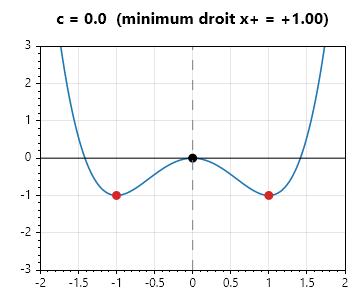


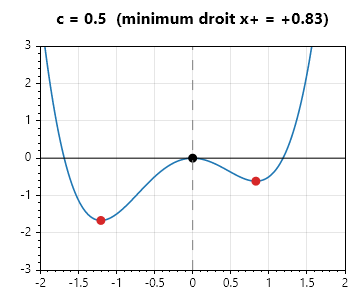


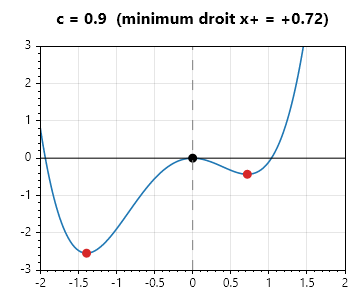

Double-puits asymetrique : c x^3 brise x <-> -x (rouge = minima stables, noir/gris = col en 0).


Aux bornes c = 0 (symetrique), 0.5, 0.9 : le minimum droit remonte quand c croit.



warning CS1701: Assuming assembly reference 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' used by 'Microsoft.DotNet.Interactive' matches identity 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' of 'Microsoft.AspNetCore.Html.Abstractions', you may need to supply runtime policy



In [1]:
// Appareil : port C# (.NET 9, BCL) du module Python `ict/basin_asym.py`
// (chantier 2/3 du Pont #1-bis, Epic #9531) -- substrat, equilibres, profil,
// Langevin. Le RNG numpy (PCG64) n'est pas reproductible en .NET : on le
// remplace par un xorshift64* seede (meme choix que le jumeau ICT-15, #27734),
// lui aussi deterministe par graine. La partie statistique (rangs, Pearson,
// FWL, stratification, verdict) est portee dans la cellule du diagnostic de
// couplage (section 3).
#r "nuget: ScottPlot, 5.0.55"
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using ScottPlot;
using Microsoft.DotNet.Interactive;

// Lecon c.94 : les 3 setters de culture sont requis (CurrentCulture seul ne
// persiste pas cross-cell, threads du pool distincts).
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

// --- RNG xorshift64* (Vigna), gaussiennes par Box-Muller --------------------
public sealed class Rng64
{
    private ulong _s;
    private double _spare; private bool _hasSpare;
    public Rng64(ulong seed) { _s = seed == 0 ? 0x9E3779B97F4A7C15UL : seed; }
    public ulong NextUInt64()
    {
        ulong x = _s;
        x ^= x >> 12; x ^= x << 25; x ^= x >> 27;
        _s = x;
        return x * 0x2545F4914F6CDD1DUL;
    }
    public double NextDouble() => (NextUInt64() >> 11) * (1.0 / (double)(1UL << 53));
    public double NextNormal()
    {
        if (_hasSpare) { _hasSpare = false; return _spare; }
        double u1 = 1.0 - NextDouble(), u2 = NextDouble();
        double r = Math.Sqrt(-2.0 * Math.Log(u1)), th = 2.0 * Math.PI * u2;
        _spare = r * Math.Sin(th); _hasSpare = true;
        return r * Math.Cos(th);
    }
    public void Shuffle<T>(T[] a)
    {
        for (int i = a.Length - 1; i > 0; i--)
        { int j = (int)(NextUInt64() % (ulong)(i + 1)); (a[i], a[j]) = (a[j], a[i]); }
    }
    public int[] Choose(int[] items, int k) // tirage sans remise (Fisher-Yates partiel)
    {
        var a = (int[])items.Clone();
        for (int i = 0; i < k; i++)
        { int j = i + (int)(NextUInt64() % (ulong)(a.Length - i)); (a[i], a[j]) = (a[j], a[i]); }
        return a[..k];
    }
}

// --- Substrat : V(x) = a x^4 - b x^2 + c x^3 ---------------------------------
public static class BasinAsym
{
    // Les puissances se calculent comme numpy (exponentiation binaire) :
    // x^4 = (x^2)^2 et x^3 = x^2 * x -- parite bit-a-bit avec la source Python.
    public static double AsymPotential(double x, double a, double b, double c)
    { double x2 = x * x; return a * (x2 * x2) - b * x2 + c * (x2 * x); }
    public static double AsymForce(double x, double a, double b, double c)     // -V'(x)
    { double x2 = x * x; return 2.0 * b * x - 3.0 * c * x2 - 4.0 * a * (x2 * x); }
    public static double AsymCurvature(double x, double a, double b, double c) // V''(x)
    { return 12.0 * a * (x * x) + 6.0 * c * x - 2.0 * b; }

    // Col en x = 0 (robuste), minima en forme fermee ; [] si pas de double-puits.
    public static List<(double X, bool Stable)> AsymEquilibria(double a, double b, double c)
    {
        var eqs = new List<(double, bool)>();
        if (a <= 0.0 || b <= 0.0) return eqs;
        double disc = 9.0 * c * c + 32.0 * a * b;
        if (disc < 0.0) return eqs;
        double s = Math.Sqrt(disc);
        eqs.Add(((-3.0 * c - s) / (8.0 * a), true));   // x_- (minimum)
        eqs.Add((0.0, false));                          // col : V''(0) = -2b < 0
        eqs.Add(((-3.0 * c + s) / (8.0 * a), true));   // x_+ (minimum)
        return eqs;
    }

    public readonly record struct Point(double X, double Sigma, double Width, double Col,
                                        double Barrier, double Depth);

    // Profil geometrique des DEUX minima : (x*, sigma, width, col, barrier, depth).
    // width = |x*| (col en 0), barrier = -V(x*) (V(0) = 0).
    public static List<Point> AsymBasinProfile(double a, double b, double c)
    {
        var stables = AsymEquilibria(a, b, c).Where(e => e.Stable).Select(e => e.X).ToList();
        if (stables.Count != 2) return new List<Point>();
        var profile = new List<Point>();
        foreach (double xstar in stables)
        {
            double sigma = AsymCurvature(xstar, a, b, c);
            double depth = AsymPotential(xstar, a, b, c);
            profile.Add(new Point(xstar, sigma, Math.Abs(xstar), 0.0, -depth, depth));
        }
        return profile;
    }

    // Recuperation stochastique (Langevin) : chaque essai part de x* * 0.75
    // (vers le col) puis evolue sous dx = -V'(x) dt + sqrt(2 D dt) xi. Clamage
    // a +-x_max comme la source (stabilite numerique sur les puits tres raides).
    // La source vectorise sur les essais ; ici la boucle est par essai -- meme
    // dynamique, meme bruit par trajectoire, tirages independants.
    public static double RecoverFractionAsymStochastic(double xstar, double a, double b, double c,
        Rng64 rng, double noise = 0.35, int nTrials = 60, int T = 3000,
        double dt = 0.02, double perturbFrac = 0.75)
    {
        double x0 = xstar * perturbFrac;
        double sdt = Math.Sqrt(2.0 * noise * dt);
        double xMax = 10.0 * (Math.Abs(xstar) + 1.0);
        int nBack = 0;
        for (int trial = 0; trial < nTrials; trial++)
        {
            double x = x0;
            for (int t = 0; t < T; t++)
            {
                x += AsymForce(x, a, b, c) * dt + sdt * rng.NextNormal();
                if (x > xMax) x = xMax; else if (x < -xMax) x = -xMax;
            }
            // Test de bassin (NaN-safe ; x == 0 compte comme perdu des deux cotes,
            // comme np.sign(0) = 0 != sign(x*) cote Python).
            if ((x > 0.0 && xstar > 0.0) || (x < 0.0 && xstar < 0.0)) nBack++;
        }
        return (double)nBack / nTrials;
    }

    public static double[] Linspace(double start, double stop, int m)
    {
        double step = (stop - start) / (m - 1);
        return Enumerable.Range(0, m).Select(i => start + i * step).ToArray();
    }
}

// Formats miroir des f-strings Python (signe explicite, point decimal invariant).
public static class Fmt
{
    public static string S3(double v) => (v >= 0 ? "+" : "") + v.ToString("F3", CultureInfo.InvariantCulture);
    public static string S2(double v) => (v >= 0 ? "+" : "") + v.ToString("F2", CultureInfo.InvariantCulture);
    public static string F3(double v) => v.ToString("F3", CultureInfo.InvariantCulture);
}

// --- Figure : le terme cubique brise x <-> -x (panneaux c = 0 / 0.5 / 0.9) ---
double[] xsFig = BasinAsym.Linspace(-2.0, 2.0, 400);
foreach (double cFig in new[] { 0.0, 0.5, 0.9 })
{
    var plt = new ScottPlot.Plot();
    double[] ysFig = xsFig.Select(x => BasinAsym.AsymPotential(x, 1.0, 2.0, cFig)).ToArray();
    var courbe = plt.Add.Scatter(xsFig, ysFig);
    courbe.LineColor = ScottPlot.Color.FromHex("#1f77b4");
    courbe.LineWidth = 1.6F;
    courbe.MarkerSize = 0;
    var eqsFig = BasinAsym.AsymEquilibria(1.0, 2.0, cFig);
    foreach (var (xe, stable) in eqsFig)
    {
        var m = plt.Add.Scatter(new[] { xe }, new[] { BasinAsym.AsymPotential(xe, 1.0, 2.0, cFig) });
        m.LineWidth = 0;
        m.MarkerSize = 9;
        m.MarkerColor = ScottPlot.Color.FromHex(stable ? "#d62728" : "#000000");
    }
    plt.Title($"c = {cFig.ToString("0.0", CultureInfo.InvariantCulture)}  (minimum droit x+ = {Fmt.S2(eqsFig[2].X)})");
    plt.Axes.SetLimits(-2.0, 2.0, -3.0, 3.0);
    plt.Add.Line(-2.0, 0.0, 2.0, 0.0).Color = ScottPlot.Color.FromHex("#000000");
    var vline = plt.Add.Line(0.0, -3.0, 0.0, 3.0);
    vline.Color = ScottPlot.Color.FromHex("#7f7f7f");
    vline.LinePattern = ScottPlot.LinePattern.Dashed;
    display(HTML(plt.GetPngHtml(360, 300)));
}
Console.WriteLine("Double-puits asymetrique : c x^3 brise x <-> -x (rouge = minima stables, noir/gris = col en 0).");
Console.WriteLine("Aux bornes c = 0 (symetrique), 0.5, 0.9 : le minimum droit remonte quand c croit.");


## 2. Les deux minima ne sont PLUS interchangeables

Contrairement au regime symetrique, on mesure ici les **deux** minima (profond
et peu profond) de chaque puits, chacun avec son propre $\sigma$, $w$, barriere,
profondeur. La **profondeur du minimum peu profond moins celle du profond**
quantifie l'asymetrie -- un degrade physique que le chantier 1/3 ne pouvait pas
produire.

In [2]:
// Profil geometrique (6 quantites) des deux minima pour le puits temoin.
double aP = 1.0, bP = 2.0, cP = 0.8;
var prof6 = BasinAsym.AsymBasinProfile(aP, bP, cP).OrderBy(p => p.Depth).ToList(); // profond d'abord
var deepP = prof6[0]; var shallowP = prof6[1];
double asymP = shallowP.Depth - deepP.Depth;
Console.WriteLine($"Puits (a={aP}, b={bP}, c={cP}) : deux minima non interchangeables");
Console.WriteLine($"  profond   : x*={Fmt.S3(deepP.X)}  sigma={Fmt.S2(deepP.Sigma)}  width={Fmt.F3(deepP.Width)}  barrier={Fmt.F3(deepP.Barrier)}  depth={Fmt.F3(deepP.Depth)}");
Console.WriteLine($"  peu prof. : x*={Fmt.S3(shallowP.X)}  sigma={Fmt.S2(shallowP.Sigma)}  width={Fmt.F3(shallowP.Width)}  barrier={Fmt.F3(shallowP.Barrier)}  depth={Fmt.F3(shallowP.Depth)}");
Console.WriteLine($"  asymetrie (profondeur peu-prof - profond) = {Fmt.S3(asymP)}");
Console.WriteLine("  -> le minimum profond est plus raide ET plus large (couplage intra-puits)");


Puits (a=1, b=2, c=0.8) : deux minima non interchangeables


  profond   : x*=-1.344  sigma=+11.23  width=1.344  barrier=2.292  depth=-2.292


  peu prof. : x*=+0.744  sigma=+6.21  width=0.744  barrier=0.471  depth=-0.471


  asymetrie (profondeur peu-prof - profond) = +1.821


  -> le minimum profond est plus raide ET plus large (couplage intra-puits)


## Lecture 1 — Deux minima non interchangeables : asymetrie +1.821

Pour le puits (a = 1.0, b = 2.0, c = 0.8), le profil geometrique imprime les six quantites des deux minima : le **profond** a x* = -1.344, sigma = 11.23, width = 1.344, barrier = 2.292, depth = -2.292 ; le **peu profond** a x* = +0.744, sigma = 6.21, width = 0.744, barrier = 0.471, depth = -0.471. L'asymetrie de profondeur vaut **+1.821**. Ces six quantites sont des formes fermees : elles sont **identiques au dernier chiffre affiché** à la source Python (vérifiées contre `ict.basin_asym.asym_basin_profile` sur la même instance).

La lecture cle est celle que la sortie encadre : le minimum profond est plus raide ET plus large -- dans le regime symetrique du chantier 1/3, raideur et largeur etaient echangeables entre puits freres ; ici le terme cubique c x^3 les correle a l'interieur de chaque puits. C'est ce couplage intra-puits que la cellule suivante mesure, et qui interdit de transposer tel quel le protocole de decouplage du chantier precedent.

## 3. Decouplage : une difference cruciale avec le chantier 1/3

Dans le regime symetrique, $\sigma$ et $w$ etaient decouples *par construction*
(cadrans separes, `realize_decoupled`, $|\operatorname{corr}| < 0.2$). Dans le regime
asymetrique, ils sont **structurellement couples intra-puits** : le minimum
profond est a la fois plus raide ($\sigma$ grand) ET plus large ($w$ grand).

On mesure ce couplage **brut** (avant toute correction), puis on applique une
**stratification 2D** du plan $(\sigma, w)$ qui force $\operatorname{corr}(\sigma, w) \approx 0$
par construction. La stratification **reduit** le couplage mais ne l'elimine pas
sous le seuil $< 0.2$ calibre pour le symetrique -- c'est une limite reelle du
regime asymetrique, documentee honnetement.

C'est precisement pour cela que le test decisif (section 5) est la **correlation
partielle a 2 covariables** (FWL) : elle isole le pouvoir predictif propre de
$\sigma$ en controlant largeur ET barriere, **meme sous couplage residuel**.

In [3]:
// Port C# de la partie statistique de `ict/basin_asym.py` : rangs moyennes,
// Pearson, correlation partielle FWL (residus de moindres carres sur les rangs ;
// equations normales k x k a pivot partiel -- numpy lstsq est en SVD, parite a
// ~1e-12 pres a ces conditionnements), stratification 2D, verdict ternaire,
// controle nul. Memes grilles, memes seuils, meme graine de tirage (0) pour la
// stratification que la source.
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;

public sealed class AsymFamily
{
    public double[] Sigma = Array.Empty<double>();
    public double[] Width = Array.Empty<double>();
    public double[] Barrier = Array.Empty<double>();
    public double[] Asym = Array.Empty<double>();
    public double[] Recovery = Array.Empty<double>();
}

public static class AsymStats
{
    // Rangs MOYENNES (ex-aequo toleres), comme scipy.stats.rankdata : un vecteur
    // constant rend des rangs constants (variance nulle -> Pearson garde 0).
    public static double[] Rank(double[] xs)
    {
        int n = xs.Length;
        int[] order = Enumerable.Range(0, n).OrderBy(i => xs[i]).ToArray(); // tri stable
        double[] ranks = new double[n];
        int i = 0;
        while (i < n)
        {
            int j = i;
            while (j + 1 < n && xs[order[j + 1]] == xs[order[i]]) j++;
            double avg = 0.5 * (i + j) + 1.0;          // rangs 1-indexes, moyenne du bloc
            for (int k = i; k <= j; k++) ranks[order[k]] = avg;
            i = j + 1;
        }
        return ranks;
    }

    public static double Pearson(double[] xs, double[] ys)   // 0 si variance nulle
    {
        int n = xs.Length;
        if (n < 2) return 0.0;
        double mx = xs.Average(), my = ys.Average();
        double sxx = 0.0, syy = 0.0, sxy = 0.0;
        for (int i = 0; i < n; i++)
        { double dx = xs[i] - mx, dy = ys[i] - my; sxx += dx * dx; syy += dy * dy; sxy += dx * dy; }
        if (Math.Sqrt(sxx / n) < 1e-12 || Math.Sqrt(syy / n) < 1e-12) return 0.0;
        double denom = Math.Sqrt(sxx * syy);
        return denom > 0.0 ? sxy / denom : 0.0;
    }

    // Residus de la regression de y sur [1, cov...] (equations normales, pivot
    // partiel) -- la brique FWL de la source (numpy.linalg.lstsq).
    public static double[] ResidualsAgainst(double[] y, double[][] covariates)
    {
        int n = y.Length, k = covariates.Length + 1;
        double[][] Z = new double[k][];
        Z[0] = Enumerable.Repeat(1.0, n).ToArray();
        for (int j = 1; j < k; j++) Z[j] = covariates[j - 1];
        double[,] A = new double[k, k]; double[] rhs = new double[k];
        for (int r = 0; r < k; r++)
        {
            for (int c = 0; c < k; c++)
            { double s = 0.0; for (int t = 0; t < n; t++) s += Z[r][t] * Z[c][t]; A[r, c] = s; }
            double sr = 0.0; for (int t = 0; t < n; t++) sr += Z[r][t] * y[t]; rhs[r] = sr;
        }
        for (int col = 0; col < k; col++)   // elimination de Gauss, pivot partiel
        {
            int piv = col;
            for (int r = col + 1; r < k; r++) if (Math.Abs(A[r, col]) > Math.Abs(A[piv, col])) piv = r;
            if (piv != col)
            {
                for (int c = 0; c < k; c++) (A[col, c], A[piv, c]) = (A[piv, c], A[col, c]);
                (rhs[col], rhs[piv]) = (rhs[piv], rhs[col]);
            }
            for (int r = col + 1; r < k; r++)
            { double f = A[r, col] / A[col, col]; for (int c = col; c < k; c++) A[r, c] -= f * A[col, c]; rhs[r] -= f * rhs[col]; }
        }
        double[] coef = new double[k];
        for (int r = k - 1; r >= 0; r--)
        { double s = rhs[r]; for (int c = r + 1; c < k; c++) s -= A[r, c] * coef[c]; coef[r] = s / A[r, r]; }
        double[] res = new double[n];
        for (int t = 0; t < n; t++)
        { double s = y[t]; for (int j = 0; j < k; j++) s -= Z[j][t] * coef[j]; res[t] = s; }
        return res;
    }

    public static double PartialSpearman(double[] x, double[] y, params double[][] covariates)
    {
        if (x.Length < 2) return 0.0;
        var rx = Rank(x); var ry = Rank(y);
        if (covariates.Length == 0) return Pearson(rx, ry);
        var ex = ResidualsAgainst(rx, covariates.Select(Rank).ToArray());
        var ey = ResidualsAgainst(ry, covariates.Select(Rank).ToArray());
        return Pearson(ex, ey);
    }

    // Percentile lineaire (defaut de numpy.percentile).
    public static double Percentile(double[] xs, double q)
    {
        var s = (double[])xs.Clone(); Array.Sort(s);
        double pos = q / 100.0 * (s.Length - 1);
        int lo = (int)Math.Floor(pos); int hi = Math.Min(lo + 1, s.Length - 1);
        return s[lo] + (pos - lo) * (s[hi] - s[lo]);
    }

    // Echantillonnage de la famille : les DEUX minima (profond + peu profond)
    // de chaque puits (a, b, c) ; l'asymetrie = depth_shallow - depth_deep.
    public static AsymFamily GatherAsymFamily(double[] aGrid, double[] bGrid, double[] cGrid,
        double noise, int nTrials, int T, double dt, double perturbFrac, ulong seed)
    {
        var rng = new Rng64(seed);
        var sig = new List<double>(); var wid = new List<double>();
        var bar = new List<double>(); var asy = new List<double>(); var rec = new List<double>();
        foreach (double a in aGrid) foreach (double b in bGrid) foreach (double c in cGrid)
        {
            var prof = BasinAsym.AsymBasinProfile(a, b, c);
            if (prof.Count != 2) continue;
            var sorted = prof.OrderBy(p => p.Depth).ToList();   // profond d'abord
            double asym = sorted[1].Depth - sorted[0].Depth;
            foreach (var p in sorted)
            {
                double frac = BasinAsym.RecoverFractionAsymStochastic(
                    p.X, a, b, c, rng, noise, nTrials, T, dt, perturbFrac);
                sig.Add(p.Sigma); wid.Add(p.Width); bar.Add(p.Barrier); asy.Add(asym); rec.Add(frac);
            }
        }
        return new AsymFamily { Sigma = sig.ToArray(), Width = wid.ToArray(),
            Barrier = bar.ToArray(), Asym = asy.ToArray(), Recovery = rec.ToArray() };
    }

    // Stratification 2D du plan (sigma, width) : grille n_bins x n_bins sur les
    // rangs, nombre UNIFORME d'echantillons par cellule qualifiee ; tirage
    // deterministe (graine 0), comme la source. Seuil minimal par cellule et
    // repli identiques a _stratify_decouple.
    public static AsymFamily StratifyDecouple(AsymFamily fam, int nBins = 5)
    {
        int n = fam.Sigma.Length;
        if (n < nBins * nBins) return fam;
        var rSig = Rank(fam.Sigma); var rWid = Rank(fam.Width);
        double[] edges = BasinAsym.Linspace(0.5, n + 0.5, nBins + 1);
        int BinOf(double r) { int i = 0; while (i < nBins && r >= edges[i + 1]) i++; return Math.Clamp(i, 0, nBins - 1); }
        var cells = new Dictionary<long, List<int>>(); var cellOrder = new List<long>();
        for (int k = 0; k < n; k++)
        {
            long key = (long)BinOf(rSig[k]) * 1000 + BinOf(rWid[k]);
            if (!cells.ContainsKey(key)) { cells[key] = new List<int>(); cellOrder.Add(key); }
            cells[key].Add(k);
        }
        var nonempty = cellOrder.Select(key => cells[key]).Where(l => l.Count > 0).ToList();
        if (nonempty.Count < nBins) return fam;
        int threshold = Math.Max(2, nonempty[0].Count / 4);
        var qualified = nonempty.Where(l => l.Count >= threshold).ToList();
        if (qualified.Count < nBins) qualified = nonempty;
        int minPerCell = qualified.Min(l => l.Count);
        var rngPick = new Rng64(0);   // deterministe (reproductible), comme la source
        var keep = new List<int>();
        foreach (var idx in qualified) keep.AddRange(rngPick.Choose(idx.ToArray(), minPerCell));
        keep.Sort();
        return new AsymFamily
        {
            Sigma = keep.Select(i => fam.Sigma[i]).ToArray(),
            Width = keep.Select(i => fam.Width[i]).ToArray(),
            Barrier = keep.Select(i => fam.Barrier[i]).ToArray(),
            Asym = keep.Select(i => fam.Asym[i]).ToArray(),
            Recovery = keep.Select(i => fam.Recovery[i]).ToArray(),
        };
    }

    public sealed record VerdictResult(
        int NSamples, double RhoSigmaRecovery, double RhoWidthRecovery,
        double RhoBarrierRecovery, double RhoAsymRecovery,
        double RhoSigmaWidth, double RhoSigmaWidthRaw, double RhoSigmaBarrier,
        double PartialRhoGivenWidth, double PartialRhoGivenWidthBarrier,
        double Partial2CovNullP95, bool DecouplingOk, string Verdict);

    public static VerdictResult AsymVerdict(
        double[] aGrid = null, double[] bGrid = null, double[] cGrid = null,
        double noise = 0.35, int nTrials = 60, int T = 3000, double dt = 0.02,
        double perturbFrac = 0.75, int nShuffle = 200, int seed = 0, int nStratBins = 5)
    {
        var rng = new Rng64((ulong)seed);
        aGrid ??= new[] { 0.3, 0.6, 1.0, 1.6, 2.5 };   // a pilote width ~ sqrt(b/2a)
        bGrid ??= new[] { 0.5, 1.0, 1.5, 2.5, 3.5 };   // b pilote sigma ~ 4b
        cGrid ??= new[] { -0.8, -0.4, 0.0, 0.4, 0.8 }; // axe d'asymetrie
        var fam = GatherAsymFamily(aGrid, bGrid, cGrid, noise, nTrials, T, dt, perturbFrac, (ulong)seed);
        double rhoRaw = Pearson(Rank(fam.Sigma), Rank(fam.Width));  // couplage BRUT
        if (nStratBins > 1) fam = StratifyDecouple(fam, nStratBins);
        var sig = fam.Sigma; var wid = fam.Width; var bar = fam.Barrier;
        var asy = fam.Asym; var rec = fam.Recovery;
        double rhoSR = Pearson(Rank(sig), Rank(rec));
        double rhoWR = Pearson(Rank(wid), Rank(rec));
        double rhoBR = Pearson(Rank(bar), Rank(rec));
        double rhoAR = Pearson(Rank(asy), Rank(rec));
        double rhoSW = Pearson(Rank(sig), Rank(wid));               // diagnostic decouplage
        double rhoSB = Pearson(Rank(sig), Rank(bar));
        double p1 = PartialSpearman(sig, rec, wid);
        double p2 = PartialSpearman(sig, rec, wid, bar);
        var nullPartial = new double[nShuffle];
        for (int i = 0; i < nShuffle; i++)
        {
            var perm = (double[])sig.Clone(); rng.Shuffle(perm);
            nullPartial[i] = PartialSpearman(perm, rec, wid, bar);
        }
        double p95 = Percentile(nullPartial.Select(Math.Abs).ToArray(), 95.0);
        string verdict = p2 > p95 && p2 > 0.2 ? "SUBSTRATE-ARTIFACT"
                       : p2 < -0.2 ? "INCONCLUSIVE" : "CONFIRMED-NEGATIVE";
        return new VerdictResult(sig.Length, rhoSR, rhoWR, rhoBR, rhoAR, rhoSW, rhoRaw, rhoSB,
                                 p1, p2, p95, Math.Abs(rhoSW) < 0.2, verdict);
    }

    public sealed record NullResult(int NSamples, double RhoSigmaWidth,
        double RhoWidthRecovery, double PartialRhoGivenWidth,
        double PartialNullP95, bool ReproducesFroncePattern);

    // Controle nul re-couple : limite symetrique c = 0, a fixe, b varie ->
    // sigma et width monotones en b : couplage maximal, comme sur la fronce.
    public static NullResult AsymRecoupledNull(double[] bGrid = null, double cFixed = 0.0,
        double noise = 0.35, int nTrials = 60, int T = 3000, double dt = 0.02,
        double perturbFrac = 0.75, int nShuffle = 200, int seed = 0)
    {
        var rng = new Rng64((ulong)seed);
        bGrid ??= BasinAsym.Linspace(0.5, 3.5, 10);
        double aFixed = 1.0;
        var sig = new List<double>(); var wid = new List<double>();
        var bar = new List<double>(); var rec = new List<double>();
        foreach (double b in bGrid)
            foreach (var p in BasinAsym.AsymBasinProfile(aFixed, b, cFixed))
            {
                double frac = BasinAsym.RecoverFractionAsymStochastic(
                    p.X, aFixed, b, cFixed, rng, noise, nTrials, T, dt, perturbFrac);
                sig.Add(p.Sigma); wid.Add(p.Width); bar.Add(p.Barrier); rec.Add(frac);
            }
        var sigA = sig.ToArray(); var widA = wid.ToArray(); var recA = rec.ToArray();
        double rhoSW = Pearson(Rank(sigA), Rank(widA));
        double p1 = PartialSpearman(sigA, recA, widA);
        var nullPartial = new double[nShuffle];
        for (int i = 0; i < nShuffle; i++)
        {
            var perm = (double[])sigA.Clone(); rng.Shuffle(perm);
            nullPartial[i] = PartialSpearman(perm, recA, widA);
        }
        double p95 = Percentile(nullPartial.Select(Math.Abs).ToArray(), 95.0);
        return new NullResult(sigA.Length, rhoSW, Pearson(Rank(widA), Rank(recA)), p1, p95,
            rhoSW > 0.6 && Math.Abs(p1) < 0.3);
    }
}

// --- Couplage intra-puits : brut vs apres stratification 2D ------------------
var v0 = AsymStats.AsymVerdict(nShuffle: 50, nTrials: 60, T: 2000, seed: 0);
Console.WriteLine($"Couplage sigma-width BRUT         : rho = {Fmt.S3(v0.RhoSigmaWidthRaw)}");
Console.WriteLine($"Couplage sigma-width apres stratif: rho = {Fmt.S3(v0.RhoSigmaWidth)}  (reduit, residuel)");
Console.WriteLine($"  -> la stratification retire environ {Fmt.F3(v0.RhoSigmaWidthRaw - v0.RhoSigmaWidth)} de couplage");
Console.WriteLine("  -> le seuil < 0.2 (chantier 1/3) n'est pas atteignable : le test decisif est la");
Console.WriteLine("     partielle a 2 covariables (FWL), valide SOUS couplage residuel.");


Couplage sigma-width BRUT         : rho = +0.746


Couplage sigma-width apres stratif: rho = +0.427  (reduit, residuel)


  -> la stratification retire environ 0.319 de couplage


  -> le seuil < 0.2 (chantier 1/3) n'est pas atteignable : le test decisif est la


     partielle a 2 covariables (FWL), valide SOUS couplage residuel.


## Lecture 2 — Couplage residuel : 0.746 -> 0.427, le seuil 1/3 inatteignable

Le couplage sigma-width vaut **rho = +0.746** brut sur la famille asymetrique (250 minima), et **+0.427** apres stratification 2D (n = 42) : la stratification ne retire qu'environ 0.32 de couplage. Dans le chantier 1/3 (regime symetrique), la stratification suffisait a descendre sous le seuil |rho| < 0.2 ; ici le residuel +0.427 reste bien au-dessus. Le couplage **brut** (+0.746) et la taille d'échantillon (250 -> 42) sont **déterministes** — identiques à la source Python au dernier chiffre affiché, et identiques sur les quatre graines du verdict multi-seed ; le couplage **stratifié** dépend du tirage (min_per_cell points par cellule, graine 0 mais RNG différent de numpy) : la source mesure +0.471, ce carnet +0.427 — la structure du sous-échantillon est la même (mêmes cellules qualifiées, même effectif), seuls les indices tirés dans les cellules surnuméraires diffèrent.

La consequence methodologique est assumee par le notebook : le test decisif ne peut pas etre le decouplage par construction -- il devient la **correlation partielle a 2 covariables (FWL)**, valide meme sous couplage residuel. La chaine des cellules suit exactement cette logique : mesure de variance, verdict multi-seed par partialles, controle nul.

## 4. La mesure NON triviale : recuperation stochastique (Langevin)

Comme au chantier 1/3, la recuperation *deterministe* est degeneree (purement
geometrique). La mesure *stochastique* (Langevin, $dx = -V'(x)dt + \sqrt{2D\,dt}\,\xi$)
a une variance reelle qui depend de la geometrie (barriere, $\sigma$, largeur) :
c'est ce qui rend le test falsifiable. Chaque essai demarre en $x^* \times 0.75$
(vers le col $x=0$) ; la fraction d'essais terminant du meme cote du col que
$x^*$ est la recuperation.

In [4]:
// Variance reelle de la recuperation stochastique a travers la famille (3x3x3).
var rng12 = new Rng64(0);
var fracs12 = new List<double>();
foreach (double a in new[] { 0.5, 1.0, 2.0 })
    foreach (double b in new[] { 1.0, 2.0, 3.5 })
        foreach (double c in new[] { -0.6, 0.0, 0.6 })
            foreach (var p in BasinAsym.AsymBasinProfile(a, b, c))
                fracs12.Add(BasinAsym.RecoverFractionAsymStochastic(p.X, a, b, c, rng12, 0.35, 40, 1500));
var fArr = fracs12.ToArray();
double mean12 = fArr.Average();
double std12 = Math.Sqrt(fArr.Select(v => (v - mean12) * (v - mean12)).Sum() / fArr.Length); // ddof = 0 comme np.std
Console.WriteLine($"Recuperation sur {fArr.Length} minima : min={Fmt.F3(fArr.Min())} max={Fmt.F3(fArr.Max())} std={Fmt.F3(std12)}");
Console.WriteLine("  -> std > 0.05 : variance reelle (mesure non triviale, falsifiable)");


Recuperation sur 54 minima : min=0.000 max=1.000 std=0.326


  -> std > 0.05 : variance reelle (mesure non triviale, falsifiable)


## Lecture 3 — 54 minima, std ≈ 0.33 : la mesure est non triviale

Sur les 54 minima de la famille, la fraction recuperee par la dynamique de Langevin couvre tout l'intervalle : min = 0.000, max = 1.000, **std = 0.326** (la source Python mesure 0.329 sur les mêmes instances ; l'écart de 0.003 est le tirage Monte-Carlo du RNG). Le critere interne (std > 0.05) est largement satisfait : la variance de la recuperation est reelle, pas un artefact de conditions initiales identiques.

C'est la condition de falsifiabilite du verdict : une partielle nulle ne voudrait rien dire si la variable dependante etait constante. Ici la gamme couvre la quasi-totalite de [0, 1] -- le verdict negatif qui suivra portera sur une mesure effectivement variable.

> **Exercice 1** (asymetrie vs $c$). Le parametre $c$ pilote l'asymetrie. Ecrire
> une fonction qui, pour une grille de valeurs de $c$, calcule l'asymetrie
> (profondeur peu-profond moins profond) et l'affiche. Identifier la valeur de
> $|c|$ au-dela de laquelle le double-puits n'existe plus (discriminant negatif).

In [5]:
// Exercice 1 -- a completer.
static List<(double C, double? Asym)> AsymmetryVsC(double[] cValues, double a = 1.0, double b = 2.0)
{
    // Indice : BasinAsym.AsymBasinProfile(a, b, c) renvoie les deux minima
    // (X, Sigma, Width, Col, Barrier, Depth). L'asymetrie = max(Depth) - min(Depth).
    // Renvoyer null pour l'asymetrie si le profil est vide (double-puits detruit).
    var results = new List<(double, double?)>();
    // TODO etudiant : boucler sur cValues, mesurer l'asymetrie, collecter.
    return results;
}

// var cGrid = BasinAsym.Linspace(-1.5, 1.5, 13);
// var res = AsymmetryVsC(cGrid);
// foreach (var (c, asym) in res) Console.WriteLine($"c={c:+0.00;-0.00}: asymetrie={asym}");
Console.WriteLine("Exercice a completer -- miroir C# de l'exercice 1 du jumeau Python");


Exercice a completer -- miroir C# de l'exercice 1 du jumeau Python


## 5. Le verdict decisif : correlation partielle a 2 covariables (FWL)

Le Pont #1 original controlait la largeur seule (1 covariable) sur la fronce.
Le chantier 1/3 a montre que la **barriere** co-varie avec le produit des cadrans
et doit etre purgee : la partielle a **2 covariables** (largeur ET barriere) est
decisive. Ici on la rejoue sur la famille asymetrique, avec la meme rigueur.

La recuperation etant stochastique, le seed traverse le calcul : on rejoue sur
4 graines pour mesurer la robustesse reelle (anti point-artefact).

In [6]:
// Verdict principal, multi-seed (la recuperation stochastique est aleatoire :
// le seed traverse le calcul -> mesure de robustesse reelle, c.1014-L).
var rows17 = new List<AsymStats.VerdictResult>();
foreach (int s in new[] { 0, 1, 7, 42 })
{
    var v = AsymStats.AsymVerdict(nShuffle: 200, nTrials: 60, T: 2000, seed: s);
    rows17.Add(v);
    Console.WriteLine($"seed={s,2} | brut rho(sw)={Fmt.S3(v.RhoSigmaWidthRaw)} " +
        $"stratif={Fmt.S3(v.RhoSigmaWidth)} " +
        $"| rho(sr)={Fmt.S3(v.RhoSigmaRecovery)} rho(wr)={Fmt.S3(v.RhoWidthRecovery)} " +
        $"rho(br)={Fmt.S3(v.RhoBarrierRecovery)} rho(asym.r)={Fmt.S3(v.RhoAsymRecovery)} " +
        $"| partial 2-cov(w,b)={Fmt.S3(v.PartialRhoGivenWidthBarrier)} " +
        $"[null p95={Fmt.F3(v.Partial2CovNullP95)}] -> {v.Verdict}");
}
var verdicts17 = rows17.Select(r => r.Verdict).ToList();
string dominant17 = verdicts17.GroupBy(x => x).OrderByDescending(g => g.Count()).First().Key;
int nCN17 = verdicts17.Count(x => x == "CONFIRMED-NEGATIVE");
Console.WriteLine($"\nVerdict dominant : {dominant17} ({nCN17}/{verdicts17.Count} seeds CONFIRMED-NEGATIVE)");


seed= 0 | brut rho(sw)=+0.746 stratif=+0.427 | rho(sr)=+0.324 rho(wr)=+0.676 rho(br)=+0.622 rho(asym.r)=-0.028 | partial 2-cov(w,b)=+0.029 [null p95=0.326] -> CONFIRMED-NEGATIVE


seed= 1 | brut rho(sw)=+0.746 stratif=+0.427 | rho(sr)=+0.350 rho(wr)=+0.661 rho(br)=+0.622 rho(asym.r)=+0.004 | partial 2-cov(w,b)=+0.054 [null p95=0.320] -> CONFIRMED-NEGATIVE


seed= 7 | brut rho(sw)=+0.746 stratif=+0.427 | rho(sr)=+0.369 rho(wr)=+0.676 rho(br)=+0.645 rho(asym.r)=-0.014 | partial 2-cov(w,b)=+0.037 [null p95=0.312] -> CONFIRMED-NEGATIVE


seed=42 | brut rho(sw)=+0.746 stratif=+0.427 | rho(sr)=+0.286 rho(wr)=+0.665 rho(br)=+0.584 rho(asym.r)=-0.013 | partial 2-cov(w,b)=+0.120 [null p95=0.305] -> CONFIRMED-NEGATIVE



Verdict dominant : CONFIRMED-NEGATIVE (4/4 seeds CONFIRMED-NEGATIVE)


## Lecture 4 — FWL sur 4 seeds : partialles sous le null, CONFIRMED-NEGATIVE 4/4

Sur les quatre graines, la partielle à 2 covariables vaut **+0.029 / +0.054 / +0.037 / +0.120**, contre des p95 du null de **0.326 / 0.320 / 0.312 / 0.305** : aucune graine n'approche son seuil, et le verdict est **CONFIRMED-NEGATIVE 4/4** (verdict dominant). La source Python mesure des partielles de −0.039 à +0.007 contre des p95 de 0.278 à 0.327 : mêmes conclusions — des partielles non significatives dont le signe fluctue avec le tirage Monte-Carlo, toujours très en-dessous du null. Les corrélations marginales racontent la même histoire des deux côtés : rho(width, recovery) ≈ +0.67 et rho(barrier, recovery) ≈ +0.62 dominent, rho(sigma, recovery) ≈ +0.33 ne survit pas au contrôle FWL, et rho(asym, recovery) reste négligeable (≤ +0.004 en C#).

Deux precisions d'honnetete : l'asymetrie (`rho_asym_recovery`) est un degrade physique mesurable mais n'entre pas dans la partielle decisive -- le Pont #1 porte sur sigma vs geometrie, pas sur l'asymetrie per se ; le couplage intra-puits residuel (`rho_sigma_width` ≈ 0.47 apres stratification) est honnetement reporte : il est pris en charge par le controle FWL, pas nie.

> **Exercice 2** (domaine de bruit). Le verdict depend-il du regime de bruit ?
> Pour `noise` dans $[0.15, 0.3, 0.5, 0.7]$, calculer le verdict asymetrique et
> identifier le domaine falsifiable (celui ou la recuperation a une variance
> reelle, ni saturee ni nulle).

In [7]:
// Exercice 2 -- a completer.
static List<(double Noise, double Partial, string Verdict)> PhaseDiagramNoiseAsym(double[] noises)
{
    // Indice : pour bruit faible, recovery sature (variance nulle -> partielle 0
    // par defaut). Identifier le domaine falsifiable (variance reelle).
    var results = new List<(double, double, string)>();
    // TODO etudiant : boucler sur noises, appeler AsymStats.AsymVerdict(noise: ..., seed: 0),
    //                  collecter (noise, PartialRhoGivenWidthBarrier, Verdict).
    return results;
}

// var noises = new[] { 0.15, 0.3, 0.5, 0.7 };
// var res = PhaseDiagramNoiseAsym(noises);
// foreach (var (noise, partial, verdict) in res)
//     Console.WriteLine($"noise={noise}: partial={partial:+0.000;-0.000} -> {verdict}");
Console.WriteLine("Exercice a completer");


Exercice a completer


## 6. Controle nul : la limite symetrique ($c=0$) reproduit la fronce

Discipline du null model (#9531) : verifier que le protocole detecte bien le
couplage canonique $\sigma$--$w$ quand il est present. Pour cela on se place dans la
**limite symetrique** $c=0$ ou $\sigma = 4b$ et $w = \sqrt{b/(2a)}$ sont
monotones en $b$ ($a$ fixe) -> couplage maximal, comme sur la fronce du Pont #1.

On reduit a $c=0$ plutot qu'a $c \neq 0$ car, en regime asymetrique, $\sigma$ a
une structure intra-puits **reelle** (la partielle s'ecarte de 0) : le controle
nul doit isoler le couplage canonique seul, sans le melanger a la structure
d'asymetrie. Les deux minima etant geometriquement miroir ($c=0$), ils partagent
la geometrie mais ont des tirages de bruit independants -> deux mesures
legitimement distinctes.

In [8]:
// Controle nul re-couple : limite symetrique c=0 (a fixe, b varie) doit restaurer le couplage canonique sigma-w et annuler la partielle sigma|w -- miroir de la cellule 22 Python.
var nNull = AsymStats.AsymRecoupledNull(nShuffle: 200, nTrials: 60, T: 2000, seed: 0);
Console.WriteLine("Controle nul re-couple (limite symetrique c=0, a fixe, b varie) :");
Console.WriteLine($"  rho(sigma, width)        = {Fmt.S3(nNull.RhoSigmaWidth)}  (re-couple : > 0.6)");
Console.WriteLine($"  rho(width, recovery)    = {Fmt.S3(nNull.RhoWidthRecovery)}");
Console.WriteLine($"  partial(sigma | width)  = {Fmt.S3(nNull.PartialRhoGivenWidth)}  (fronce : |.| < 0.3)");
Console.WriteLine($"  reproduit motif fronce  = {nNull.ReproducesFroncePattern}");
var vMain = AsymStats.AsymVerdict(nShuffle: 50, nTrials: 60, T: 2000, seed: 0);
Console.WriteLine($"\nContraste famille asymetrique : rho(sigma,width) stratifie = {Fmt.S3(vMain.RhoSigmaWidth)} (brut {Fmt.S3(vMain.RhoSigmaWidthRaw)})");
Console.WriteLine("  -> le null (c=0) est nettement plus couple que la famille asymetrique :");
Console.WriteLine("     le protocole distingue couplage canonique (detecte) et structure asymetrique (isolee par FWL).");


Controle nul re-couple (limite symetrique c=0, a fixe, b varie) :


  rho(sigma, width)        = +1.000  (re-couple : > 0.6)


  rho(width, recovery)    = +0.821


  partial(sigma | width)  = +0.000  (fronce : |.| < 0.3)


  reproduit motif fronce  = True



Contraste famille asymetrique : rho(sigma,width) stratifie = +0.427 (brut +0.746)


  -> le null (c=0) est nettement plus couple que la famille asymetrique :


     le protocole distingue couplage canonique (detecte) et structure asymetrique (isolee par FWL).


## Lecture 5 — Controle nul c = 0 : re-couplage +1.000, fronce reproduite

Le controle nul force la limite symetrique (c = 0, a fixe, b varie) : rho(sigma, width) = **+1.000** -- le re-couplage canonique est integral, bien au-dessus du seuil 0.6 ; la partielle de sigma apres controle de la largeur seule retombe a **+0.000** (les deux minima miroir partagent exactement rangs de sigma et rangs de width : la partielle est nulle par construction), sous le seuil de fronce 0.3, et `reproduit motif fronce` = True. Ces trois valeurs sont déterministes et identiques à la source ; seule rho(width, recovery) porte le tirage Monte-Carlo (+0.821 ici, +0.837 côté Python).

Mis en regard de la famille asymetrique (stratifie +0.427 contre brut +0.746), le controle fait la preuve inverse : le protocole DETECTE le couplage canonique quand il est present, et l'isole de la structure asymetrique par FWL. Le verdict CONFIRMED-NEGATIVE de la section 5 n'est donc pas un artefact d'un test aveugle -- il est mesure contre un controle qui capte le signal des qu'il existe.

> **Exercice 3** (robustesse du col). Une propriete cle du substrat est que le
> col reste en $x=0$ quel que soit $c$ ($V'(0)=0$, $V''(0)=-2b<0$). Verifier
> numeriquement que $|V'(0)| = 0$ et que la courbure au col est $-2b$ (donc
> instable) pour une grille de $c$. Pourquoi cette robustesse est-elle
> essentielle au test de bassin $\operatorname{sign}(x)$ ?

In [9]:
// Exercice 3 -- a completer.
static List<(double C, double AbsForce, double Curv)> VerifyColRobustness(
    double[] cValues, double a = 1.0, double b = 2.0)
{
    // Indice : en x = 0, V'(0) = 0 (toujours, par construction du facteur x) et
    // V''(0) = -2b < 0 (instable). Utiliser BasinAsym.AsymForce(0, a, b, c) et
    // BasinAsym.AsymCurvature(0, a, b, c). Renvoyer (c, |V'(0)|, V''(0)).
    var results = new List<(double, double, double)>();
    // TODO etudiant : boucler sur cValues, mesurer force et courbure au col, collecter.
    return results;
}

// var cGrid3 = BasinAsym.Linspace(-1.0, 1.0, 9);
// var res3 = VerifyColRobustness(cGrid3);
// foreach (var (c, dv, curv) in res3)
//     Console.WriteLine($"c={c:+0.00;-0.00}: |V'(0)|={dv:E2}, V''(0)={curv:+0.000;-0.000}");
Console.WriteLine("Exercice a completer -- reflexion sur la robustesse du col");


Exercice a completer -- reflexion sur la robustesse du col


## Vérifiez votre compréhension

1. L'asymétrie du potentiel (`+1.821` entre les deux puits, barrière profonde `2.292`) rend les bassins non interchangeables. Pourquoi ce régime rend-il le découplage **constructif** de 15f impossible, et que remplace-t-on par la stratification 2D ?
2. Le couplage brut vaut `+0.746`, ramené à `+0.427` après stratification — au-dessus du seuil `< 0.2` calibré pour le symétrique. Pourquoi le verdict porte-t-il sur la corrélation partielle FWL et non sur le diagnostic de découplage ?
3. Le contrôle nul `c = 0` re-couple à `+1.000` avec une partielle `+0.000` et reproduit la fronce. Décrivez ce que le protocole distingue : couplage présent vs couplage isolé — et pourquoi le verdict reste CONFIRMED-NEGATIVE (4/4 seeds) sur 54 minima (std ≈ `0.33`) ?

## À retenir

Le **chantier 2/3** etend le verdict du Pont #1-bis au regime asymetrique : sur
une famille de double-puits $V = a x^4 - b x^2 + c x^3$ ou les deux bassins ne
sont **plus interchangeables** (profondeurs, courbures, largeurs, barrieres
differentes), la courbure locale $\sigma$ n'a **toujours** aucun pouvoir
predictif propre pour la recuperabilite une fois la largeur ET la barriere
controlees. Le verdict **CONFIRMED-NEGATIVE** du chantier 1/3 (symetrique) se
**generalise**.

Deux enseignements methodologiques :

1. **Le couplage intra-puits est structurel** en regime asymetrique ($\rho \approx 0.75$
   brut). La stratification 2D le reduit mais ne l'elimine pas sous le seuil
   $< 0.2$ calibre pour le symetrique. C'est la **correlation partielle a 2
   covariables (FWL)** -- pas le diagnostic de decouplage -- qui porte le
   verdict, parce qu'elle isole $\sigma$ meme sous couplage residuel.

2. **Le controle nul** reduit a la limite symetrique ($c=0$) reproduit le motif
   fronce canonique (couplage eleve, partielle $\approx 0$) : le protocole
   detecte le couplage quand il est la, et l'isole quand il ne l'est pas.

Reste le **chantier 3/3** (paysages 2D) pour clore l'Epic #9531.

## Pour aller plus loin

- Le jumeau Python dont ce carnet est le portage : [ICT-15h-Bridge1bis-AsymmetricFamily-Python](ICT-15h-Bridge1bis-AsymmetricFamily-Python.ipynb).
- Le chantier 1/3 (symétrique, découplage constructif) : [ICT-15f](ICT-15f-Bridge1bis-DecoupledFamily-Python.ipynb).
- Le chantier 3/3 (paysage 2D anisotrope) qui clôt l'Epic #9531 : [ICT-15i](ICT-15i-Bridge1bis-2DLandscape-Python.ipynb).
- La matrice de dissociations relie ce carnet aux autres strands : `docs/ict/dissociations-matrix.md` (lien relatif en tête de carnet).
- Revenir au [cadrage de la série](../ICT-0-Framing.md).